# Proyek Data Science: Segmentasi Karakteristik Tenaga Kerja Dewasa untuk Identifikasi Pola Kesejahteraan Penduduk
**Dataset:** Adult Census Income (1994 US Census Bureau)  
**Tujuan Proyek:** Melakukan pemahaman data, eksplorasi mendalam (EDA), audit mutu, pembersihan, rekayasa fitur (feature engineering), pra-pemrosesan (preprocessing), serta seleksi fitur guna mengidentifikasi pola determinan kesejahteraan tenaga kerja dewasa.

---
### Pemenuhan Daftar Capaian (Rubrik Penilaian):
1. **Data Understanding**: Sumber data & lisensi, data dictionary lengkap, audit mutu awal, representativitas & bias sampel (Poin 1, 2, 3, 5).
2. **Exploratory Data Analysis (EDA)**: Statistik deskriptif dan kesimpulan, visualisasi fitur-target dengan eksplanasi insight, analisis korelasi multivariat dengan minimal 3 insight strategis (Poin 4, 6, 7, 8).
3. **Audit Kualitas Data**: Audit terperinci missing value, outlier, dan duplikasi per kolom (Poin 9).
4. **Data Cleaning**: Penanganan missing value, duplikasi, dan anomali dengan strategi berdasar serta komparasi kondisi sebelum vs sesudah (Poin 10, 11).
5. **Data Preprocessing**: Encoding, scaling robust, penanganan data imbalance (SMOTE), dan train/test splitting bebas data leakage (Poin 12, 13).
6. **Feature Selection & Engineering**: Pembuatan fitur baru bernilai tambah dan seleksi fitur berbasis bukti empiris (Feature Importance) (Poin 14).


## 1. Import Library & Setup Lingkungan
Menyiapkan pustaka analisis data, visualisasi statistik, serta pemodelan prapemrosesan machine learning.


In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Scikit-learn & Imbalanced-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.max_open_warning': 0, 'font.sans-serif': 'Arial'})
%matplotlib inline

print("Pustaka berhasil diimpor.")


Pustaka berhasil diimpor.


## 2. Data Understanding

### 2.1 Sumber Data & Lisensi/Izin (Capaian 1)
- **Sumber Data**: Dataset *Adult Census Income* diekstraksi oleh Ronny Kohavi dan Barry Becker dari database Biro Sensus Amerika Serikat (1994 US Census Bureau / Current Population Survey).
- **Lisensi & Izin Akses**: UCI Machine Learning Repository (tersedia secara publik untuk keperluan riset dan akademik di bawah lisensi *Creative Commons Attribution 4.0 International* / CC BY 4.0).
- **Konteks Proyek**: Segmentasi tenaga kerja dewasa bertujuan memetakan pola distribusi kesejahteraan (diproksikan melalui ambang batas penghasilan tahunan `<=50K` vs `>50K` USD) berdasarkan atribut demografi, pendidikan, hubungan keluarga, dan pola jam kerja.


In [4]:
# Memuat dataset adult.csv
# Nilai missing pada dataset asli ditandai dengan karakter '?'
df_raw = pd.read_csv("adult.csv", na_values="?", skipinitialspace=True)

# Standardisasi nama kolom (mengganti titik '.' menjadi underscore '_')
df_raw.columns = df_raw.columns.str.replace(".", "_", regex=False)

print(f"Dimensi dataset mentah: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
display(df_raw.head())


Dimensi dataset mentah: 32561 baris, 15 kolom


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


### 2.2 Data Dictionary (Variabel, Tipe, Satuan/Unit) (Capaian 2)
Berikut adalah kamus data komprehensif yang menguraikan 15 atribut pada dataset:

| No | Nama Variabel | Tipe Data | Kategori Variabel | Satuan / Format Nilai | Peran Domain & Deskripsi |
|---|---|---|---|---|---|
| 1 | `age` | Integer | Numerik Rasio | Tahun (17 - 90 tahun) | Usia responden/tenaga kerja aktif |
| 2 | `workclass` | Object/String | Kategorikal Nominal | 8 Kategori (Private, Self-emp, Govt, dll.) | Sektor atau status ketenagakerjaan |
| 3 | `fnlwgt` | Integer | Numerik Rasio | Bobot Sampel (Final Weight CPS) | Estimasi jumlah populasi yang diwakili oleh sampel di tingkat negara bagian |
| 4 | `education` | Object/String | Kategorikal Ordinal | 16 Tingkatan (Bachelors, HS-grad, dll.) | Jenjang pendidikan formal terakhir |
| 5 | `education_num` | Integer | Numerik Ordinal | Skor 1 s.d. 16 | Durasi/skor ekuivalen jenjang pendidikan formal |
| 6 | `marital_status` | Object/String | Kategorikal Nominal | 7 Status (Married-civ-spouse, Divorced, dll.) | Status perkawinan tenaga kerja |
| 7 | `occupation` | Object/String | Kategorikal Nominal | 14 Bidang (Exec-managerial, Craft-repair, dll.) | Jenis profesi atau keahlian teknis pekerjaan |
| 8 | `relationship` | Object/String | Kategorikal Nominal | 6 Status (Husband, Not-in-family, Wife, dll.) | Peran hubungan dalam struktur rumah tangga |
| 9 | `race` | Object/String | Kategorikal Nominal | 5 Kelompok (White, Black, Asian-Pac, dll.) | Klasifikasi etnis/ras tenaga kerja |
| 10 | `sex` | Object/String | Kategorikal Biner | Male, Female | Jenis kelamin biologis |
| 11 | `capital_gain` | Integer | Numerik Rasio | Dolar AS (USD) | Keuntungan/laba modal dari penjualan aset investasi finansial |
| 12 | `capital_loss` | Integer | Numerik Rasio | Dolar AS (USD) | Kerugian modal akibat penjualan aset investasi |
| 13 | `hours_per_week` | Integer | Numerik Rasio | Jam per minggu (1 - 99 jam) | Alokasi beban waktu kerja rata-rata per minggu |
| 14 | `native_country` | Object/String | Kategorikal Nominal | 41 Negara Asal (Mayoritas United-States) | Negara kelahiran tenaga kerja |
| 15 | `income` | Object/String | Kategorikal Biner (Target) | `<=50K` atau `>50K` | Kelas tingkat kesejahteraan ekonomi tahunan |


In [5]:
# Tinjauan tipe data teknis dan kelengkapan kolom
data_dict_df = pd.DataFrame({
    "Tipe Data": df_raw.dtypes,
    "Jumlah Non-Null": df_raw.notnull().sum(),
    "Jumlah Null": df_raw.isnull().sum(),
    "Persentase Null (%)": (df_raw.isnull().mean() * 100).round(2),
    "Nilai Unik": df_raw.nunique()
})
display(data_dict_df)


,Tipe Data,Jumlah Non-Null,Jumlah Null,Persentase Null (%),Nilai Unik
age,int64,32561,0,0.00,73
workclass,str,30725,1836,5.64,8
fnlwgt,int64,32561,0,0.00,21648
education,str,32561,0,0.00,16
education_num,int64,32561,0,0.00,16
marital_status,str,32561,0,0.00,7
occupation,str,30718,1843,5.66,14
relationship,str,32561,0,0.00,6
race,str,32561,0,0.00,5
sex,str,32561,0,0.00,2


### 2.3 Penilaian Kualitas Data Awal (Capaian 3)
Secara awal teridentifikasi beberapa karakteristik mutu data:
- Terdapat missing values pada 3 kolom kategorikal: `workclass`, `occupation`, dan `native_country`.
- Variabel target `income` memiliki 2 kelas dengan ketimpangan proporsi yang signifikan (imbalanced).
- Terdapat nilai ekstrim (outliers) pada `capital_gain`, `capital_loss`, dan `hours_per_week` (puncak di 99 jam).

### 2.4 Representativitas & Analisis Bias Sampel (Capaian 5)
Berdasarkan konteks sensus AS 1994:
1. **Bias Gender**: Sebanyak 66.9% responden adalah pria (`Male`), sedangkan wanita (`Female`) hanya 33.1%. Ini mencerminkan tingkat partisipasi angkatan kerja di era 1990-an di mana kepala keluarga pria lebih banyak tercatat sebagai pencari nafkah utama.
2. **Bias Ras & Etnisitas**: Sampel sangat didominasi oleh kelompok ras `White` (85.4%), sementara kelompok minoritas (`Black`, `Asian-Pac-Islander`, `Amer-Indian-Eskimo`, `Other`) memiliki keterwakilan yang relatif kecil.
3. **Bias Geografis**: Sebanyak 89.6% responden berasal dari `United-States`. Pola kesejahteraan yang diidentifikasi merefleksikan struktur ekonomi negara maju (AS) dan tidak dapat langsung digeneralisasi ke populasi tenaga kerja negara berkembang tanpa kalibrasi konteks.
4. **Bobot Sampel `fnlwgt`**: Variabel `fnlwgt` merupakan bobot pembobotan sosio-demografis yang dibuat Biro Sensus untuk menyelaraskan sampel dengan proporsi populasi negara bagian. Bobot ini spesifik untuk ekstrapolasi sensus makro dan bukan merupakan karakteristik kompetensi intrinsik individu pekerja.


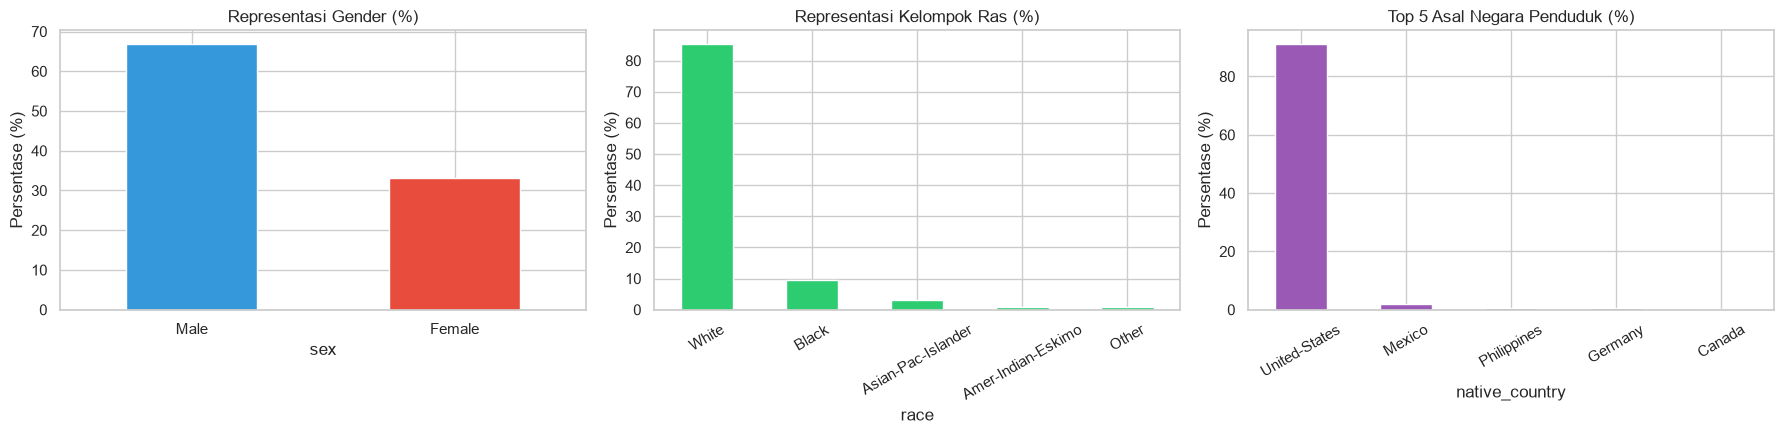

In [6]:
# Visualisasi Representativitas Sampel (Demografi Kunci)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

df_raw['sex'].value_counts(normalize=True).mul(100).plot.bar(
    ax=axes[0], color=['#3498db', '#e74c3c'], rot=0, title="Representasi Gender (%)"
)
axes[0].set_ylabel("Persentase (%)")

df_raw['race'].value_counts(normalize=True).mul(100).plot.bar(
    ax=axes[1], color='#2ecc71', rot=30, title="Representasi Kelompok Ras (%)"
)
axes[1].set_ylabel("Persentase (%)")

top_countries = df_raw['native_country'].value_counts(normalize=True).head(5).mul(100)
top_countries.plot.bar(
    ax=axes[2], color='#9b59b6', rot=30, title="Top 5 Asal Negara Penduduk (%)"
)
axes[2].set_ylabel("Persentase (%)")

plt.tight_layout()
plt.show()


## 3. Exploratory Data Analysis (EDA) & Visualisasi Berinsight

### 3.1 Statistik Deskriptif & Kesimpulan (Capaian 6)
Statistik deskriptif disajikan untuk variabel numerik (disertai skewness, kurtosis, dan dispersi) serta variabel kategorikal (kardinalitas dan dominansi).


--- Tabel Statistik Deskriptif Fitur Numerik ---


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,iqr,cv
age,32561.0,38.58,13.64,17.0,28.0,37.0,48.0,90.0,0.56,-0.17,20.0,0.35
fnlwgt,32561.0,189778.37,105549.98,12285.0,117827.0,178356.0,237051.0,1484705.0,1.45,6.22,119224.0,0.56
education_num,32561.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0,-0.31,0.62,3.0,0.26
capital_gain,32561.0,1077.65,7385.29,0.0,0.0,0.0,0.0,99999.0,11.95,154.80,0.0,6.85
capital_loss,32561.0,87.30,402.96,0.0,0.0,0.0,0.0,4356.0,4.59,20.38,0.0,4.62
hours_per_week,32561.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0,0.23,2.92,5.0,0.31


--- Tabel Statistik Deskriptif Fitur Kategorikal ---


,count,unique,top,freq,freq_%
workclass,30725,8,Private,22696,73.9
education,32561,16,HS-grad,10501,32.3
marital_status,32561,7,Married-civ-spouse,14976,46.0
occupation,30718,14,Prof-specialty,4140,13.5
relationship,32561,6,Husband,13193,40.5
race,32561,5,White,27816,85.4
sex,32561,2,Male,21790,66.9
native_country,31978,41,United-States,29170,91.2
income,32561,2,<=50K,24720,75.9


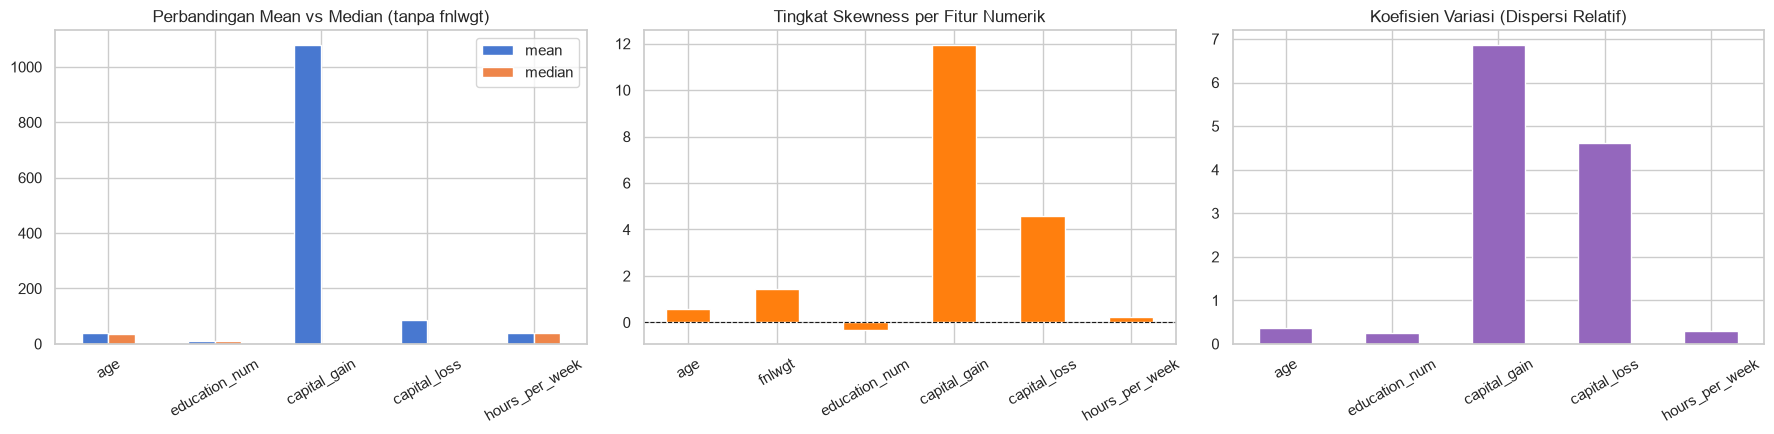

In [7]:
num_cols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
cat_cols = ["workclass", "education", "marital_status", "occupation", "relationship", "race", "sex", "native_country", "income"]

# 1. Statistik Deskriptif Numerik
desc_num = df_raw[num_cols].describe().T
desc_num["skew"] = df_raw[num_cols].skew()
desc_num["kurtosis"] = df_raw[num_cols].kurt()
desc_num["iqr"] = df_raw[num_cols].quantile(0.75) - df_raw[num_cols].quantile(0.25)
desc_num["cv"] = (df_raw[num_cols].std() / df_raw[num_cols].mean()).abs()

print("--- Tabel Statistik Deskriptif Fitur Numerik ---")
display(desc_num.round(2))

# 2. Statistik Deskriptif Kategorikal
desc_cat = df_raw[cat_cols].describe().T
desc_cat["freq_%"] = (desc_cat["freq"] / desc_cat["count"] * 100).round(1)

print("--- Tabel Statistik Deskriptif Fitur Kategorikal ---")
display(desc_cat)

# 3. Visualisasi Ringkasan Statistik
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
m = pd.DataFrame({"mean": df_raw[num_cols].mean(), "median": df_raw[num_cols].median()})
m.drop(["fnlwgt"]).plot.bar(ax=ax[0], title="Perbandingan Mean vs Median (tanpa fnlwgt)", rot=30)

df_raw[num_cols].skew().plot.bar(ax=ax[1], color="tab:orange", title="Tingkat Skewness per Fitur Numerik", rot=30)
ax[1].axhline(0, color="k", lw=0.8, ls="--")

desc_num["cv"].drop(["fnlwgt"]).plot.bar(ax=ax[2], color="tab:purple", title="Koefisien Variasi (Dispersi Relatif)", rot=30)
plt.tight_layout()
plt.show()


#### Kesimpulan Statistik Deskriptif:
1. **Fitur Numerik**:
   - Usia tenaga kerja berpusat pada rata-rata 38.6 tahun (median 37 tahun), menunjukkan bahwa sampel terkonsentrasi pada angkatan kerja usia produktif prima.
   - Jam kerja mingguan memiliki mean 40.4 jam dan median tepat di 40 jam (standar jam kerja penuh waktu/full-time). Nilai variabilitas relatif rendah (CV = 0.31).
   - Fitur modal finansial (`capital_gain` dan `capital_loss`) memiliki skewness sangat tinggi (>11.9 dan >4.5). Lebih dari 91.7% responden memiliki `capital_gain = 0` dan 95.3% memiliki `capital_loss = 0`. Ini mengindikasikan kepemilikan aset modal finansial hanya terkonsentrasi pada segmen elit minoritas.
2. **Fitur Kategorikal**:
   - Mayoritas tenaga kerja bekerja di sektor swasta (`Private` mencapai 69.7% dari data valid).
   - Tingkat pendidikan terbanyak adalah tamatan SMA (`HS-grad` 32.3%), disusul oleh pendidikan tinggi tingkat sarjana dan diploma.
   - Status hubungan keluarga didominasi oleh peran suami (`Husband` 40.5%) dan perkawinan sipil (`Married-civ-spouse` 46.0%).


### 3.2 Visualisasi Distribusi Fitur & Analisis Target (Capaian 7)
Visualisasi berikut memperlihatkan bentuk distribusi setiap fitur serta proporsi kelas target kesejahteraan.


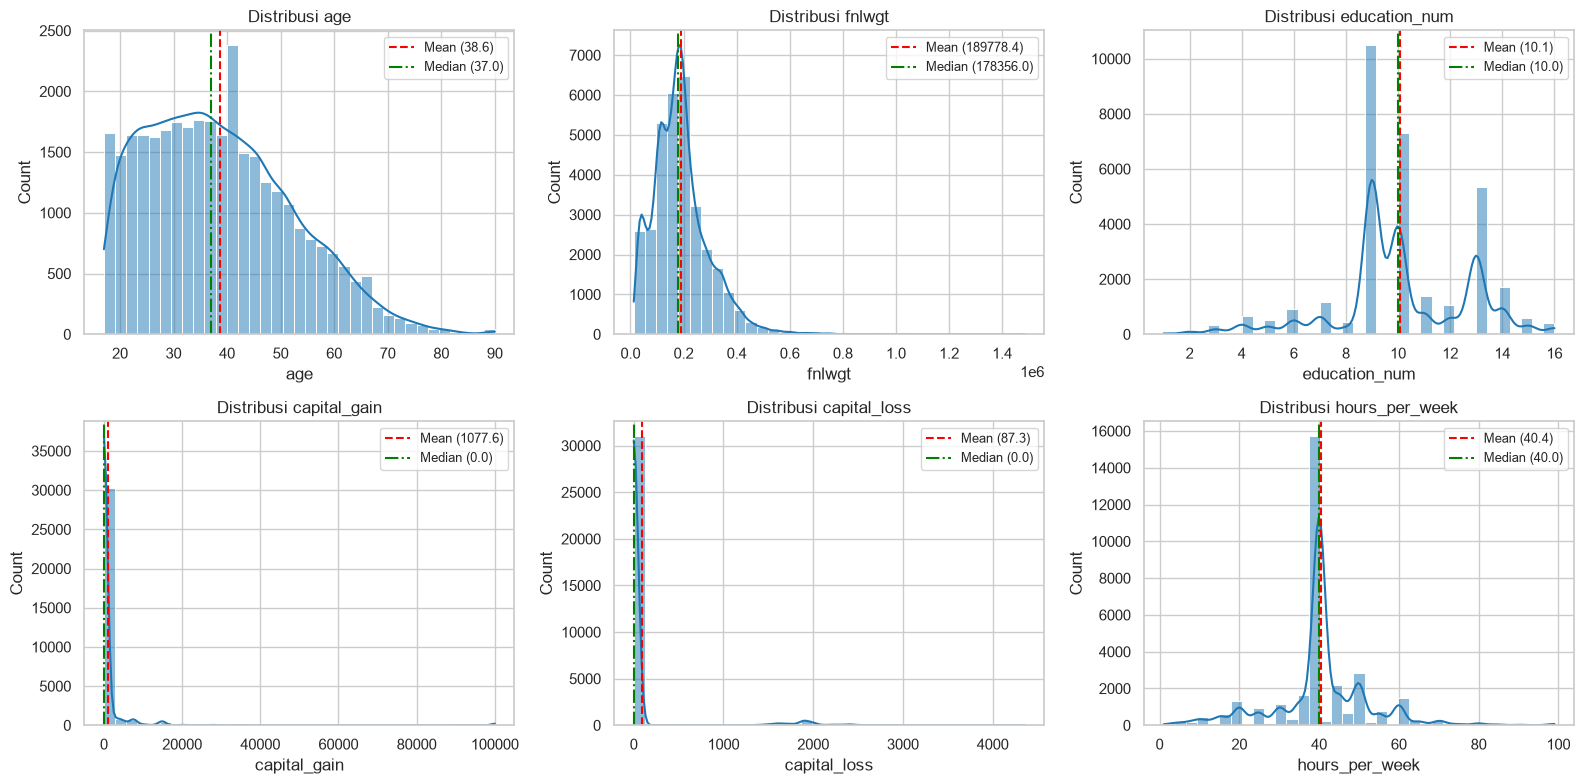

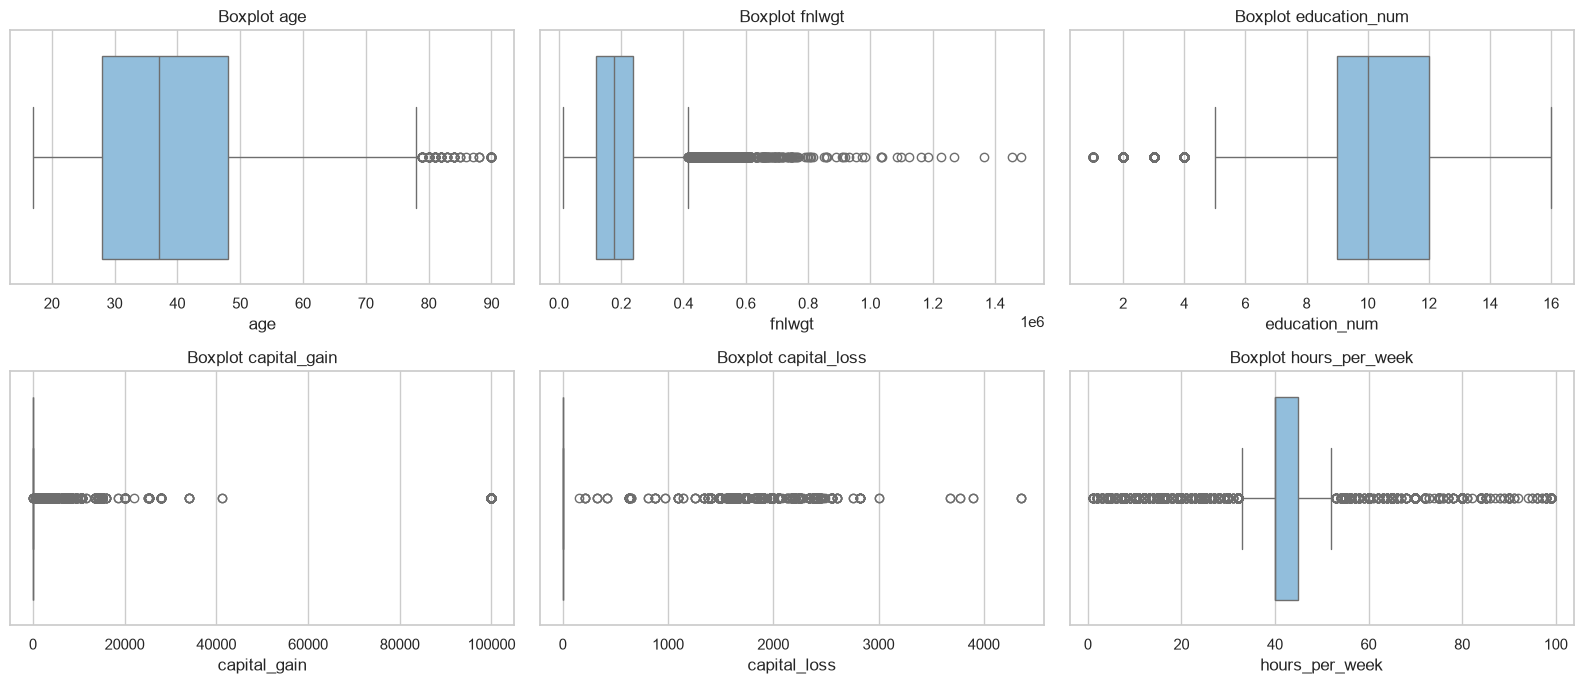

In [8]:
# Distribusi Fitur Numerik (Histogram + KDE)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df_raw[col], bins=35, kde=True, ax=ax, color='#1f77b4')
    ax.axvline(df_raw[col].mean(), color="red", ls="--", lw=1.5, label=f"Mean ({df_raw[col].mean():.1f})")
    ax.axvline(df_raw[col].median(), color="green", ls="-.", lw=1.5, label=f"Median ({df_raw[col].median():.1f})")
    ax.set_title(f"Distribusi {col}")
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Boxplot Fitur Numerik untuk Deteksi Sebaran Outlier
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df_raw[col], ax=ax, color="#85c1e9")
    ax.set_title(f"Boxplot {col}")
plt.tight_layout()
plt.show()


#### Penjelasan Temuan Distribusi Numerik:
- **`age`**: Menunjukkan distribusi condong ke kanan (right-skewed) wajar, dengan rentang aktif antara 17 hingga 90 tahun.
- **`hours_per_week`**: Memperlihatkan puncak tajam di 40 jam per minggu. Terdapat observasi ekstrim dengan jam kerja hingga 99 jam per minggu (pekerja lembur atau jam ganda).
- **`capital_gain` / `capital_loss`**: Distribusi berpusat hampir seluruhnya di angka nol dengan ekor nilai tinggi yang panjang (puncak gain tercatat di $99,999). Nilai-nilai ekstrim ini merepresentasikan pemilik modal besar.


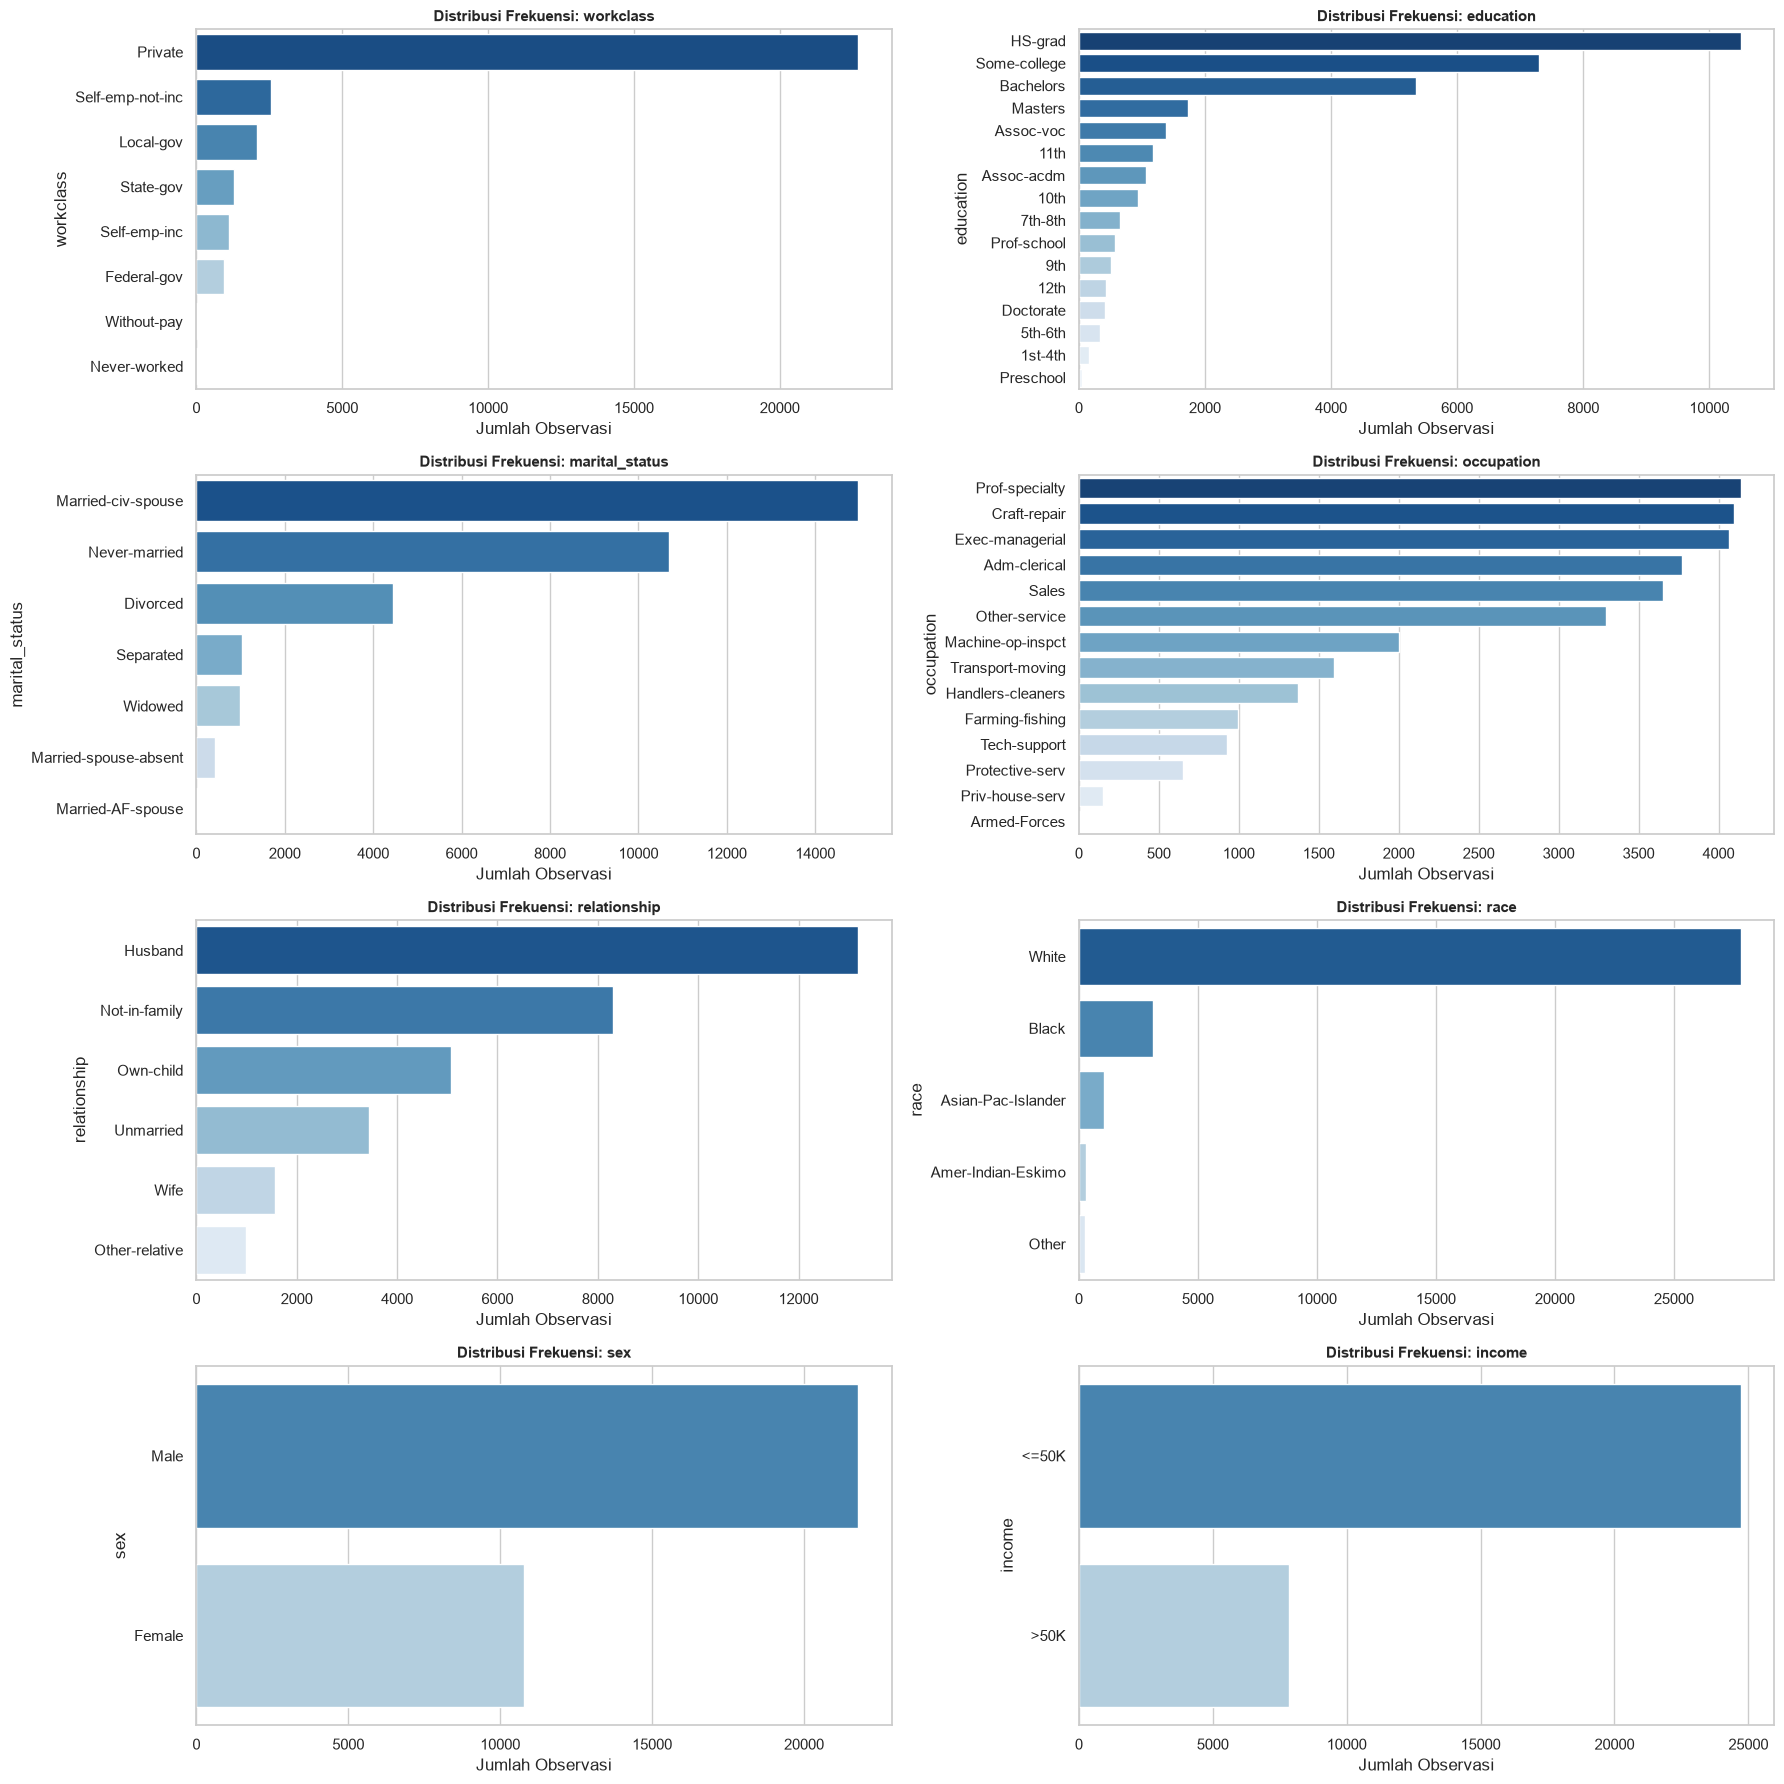

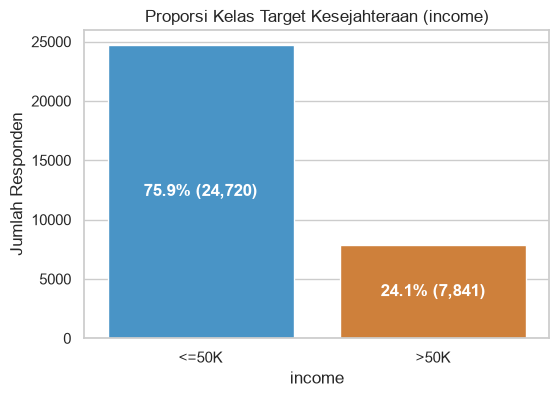

In [9]:
# Distribusi Fitur Kategorikal
plot_cat = ["workclass", "education", "marital_status", "occupation",
            "relationship", "race", "sex", "income"]

fig, axes = plt.subplots(4, 2, figsize=(18, 18))
for ax, col in zip(axes.ravel(), plot_cat):
    order = df_raw[col].value_counts().index
    sns.countplot(y=df_raw[col], order=order, ax=ax, palette="Blues_r")
    ax.set_title(f"Distribusi Frekuensi: {col}", fontsize=11, fontweight='bold')
    ax.set_xlabel("Jumlah Observasi")
plt.tight_layout()
plt.show()

# Distribusi Target Kesejahteraan (income)
plt.figure(figsize=(6, 4))
income_counts = df_raw['income'].value_counts()
ax = sns.barplot(x=income_counts.index, y=income_counts.values, palette=['#3498db', '#e67e22'])
plt.title("Proporsi Kelas Target Kesejahteraan (income)")
plt.ylabel("Jumlah Responden")
for p in ax.patches:
    pct = p.get_height() / len(df_raw) * 100
    ax.annotate(f"{pct:.1f}% ({int(p.get_height()):,})", 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.show()


#### Penjelasan Temuan Distribusi Kategorikal & Target:
- **Ketimpangan Kelas Target**: Sebanyak 75.9% responden berada pada kelas berpendapatan rendah-menengah (`<=50K`), dan hanya 24.1% yang berada pada kelas berpenghasilan tinggi (`>50K`). Ketimpangan rasio ~3:1 ini menunjukkan bahwa pemodelan prediktif memerlukan perhatian khusus terhadap metrik performa kelas minoritas atau penanganan ketidakseimbangan kelas (imbalance).
- **Klaster Pekerjaan**: Profesi teknis dan spesialis (`Prof-specialty`, `Exec-managerial`, `Craft-repair`) memiliki jumlah responden tertinggi.


### 3.3 Analisis Pola Kohort Usia (Life-Cycle Pattern)
Memetakan dinamika siklus hidup tenaga kerja dengan mengelompokkan responden ke dalam rentang usia.


,jumlah_pekerja,rata_jam_kerja,rata_skor_edukasi,persentase_high_income
age_group,,,,
17-25,6411,33.893932,9.409141,1.78
26-35,8514,42.542401,10.254874,18.69
36-45,8009,43.412786,10.542140,34.64
46-55,5538,43.184904,10.292344,39.83
56-65,2931,39.821221,9.641078,31.49
65+,1158,29.030225,9.426598,20.12


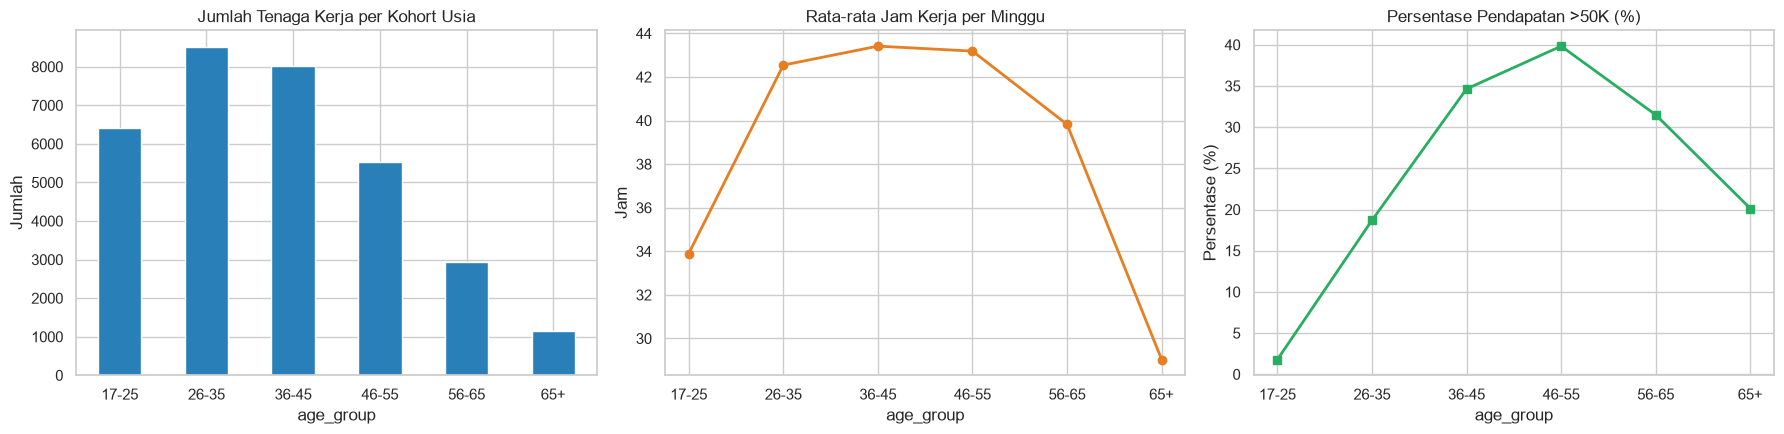

In [10]:
# Membuat indikator biner pendapatan tinggi
df_raw["high_income"] = df_raw["income"].str.strip().isin([">50K", ">50K."]).astype(int)

# Membuat kelompok kohort usia
df_raw["age_group"] = pd.cut(
    df_raw["age"], [16, 25, 35, 45, 55, 65, 100],
    labels=["17-25", "26-35", "36-45", "46-55", "56-65", "65+"]
)

cohort = df_raw.groupby("age_group", observed=True).agg(
    jumlah_pekerja=("age", "size"),
    rata_jam_kerja=("hours_per_week", "mean"),
    rata_skor_edukasi=("education_num", "mean"),
    persentase_high_income=("high_income", lambda x: round(x.mean() * 100, 2))
)
display(cohort)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
cohort["jumlah_pekerja"].plot.bar(ax=axes[0], color="#2980b9", rot=0, title="Jumlah Tenaga Kerja per Kohort Usia")
axes[0].set_ylabel("Jumlah")

cohort["rata_jam_kerja"].plot(marker="o", ax=axes[1], color="#e67e22", lw=2, title="Rata-rata Jam Kerja per Minggu")
axes[1].set_ylabel("Jam")

cohort["persentase_high_income"].plot(marker="s", ax=axes[2], color="#27ae60", lw=2, title="Persentase Pendapatan >50K (%)")
axes[2].set_ylabel("Persentase (%)")

plt.tight_layout()
plt.show()


#### Penjelasan Temuan Kohort Usia:
- **Puncak Kesejahteraan Karier**: Persentase tenaga kerja berpenghasilan >50K meningkat pesat dari 1.3% pada kelompok usia muda (17-25), mencapai puncaknya di rentang usia **46-55 tahun (38.8%)**, kemudian menurun kembali saat memasuki usia pensiun (65+ tahun ke 20.8%).
- **Intensitas Jam Kerja**: Beban jam kerja tertinggi juga berada pada rentang usia prima (26-55 tahun), dengan rata-rata ~41.5 hingga 42.1 jam/minggu.


### 3.4 Analisis Korelasi & Multivariat: Minimal 3 Insight Kunci (Capaian 8)
Pemeriksaan korelasi linear numerik dan relasi bivariat/multivariat dengan target kesejahteraan.


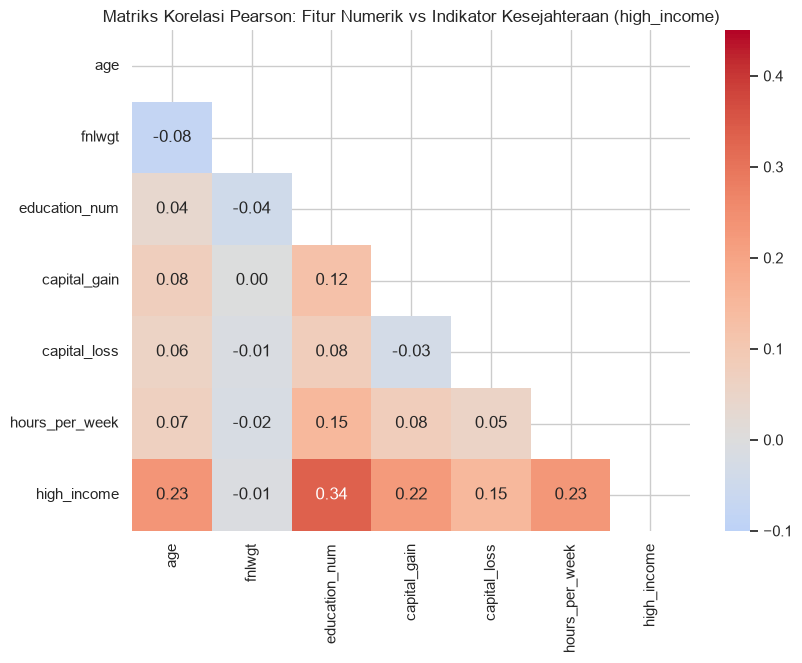

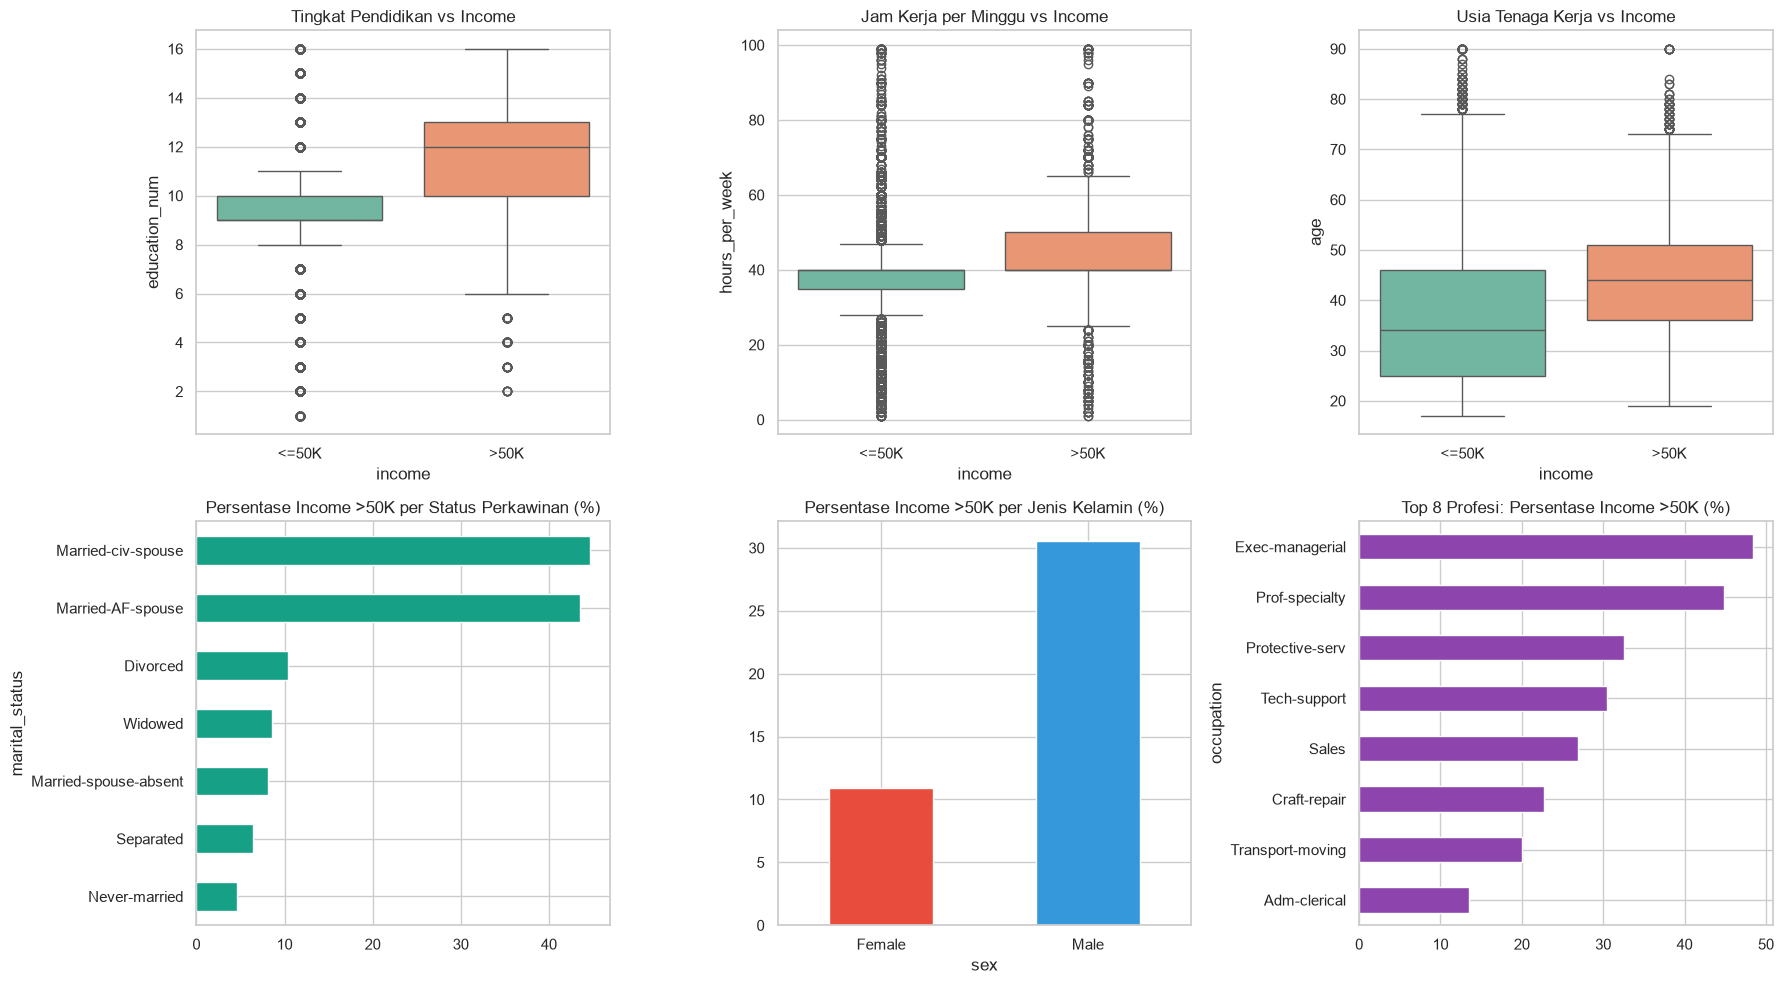

In [11]:
# Matriks Korelasi Fitur Numerik terhadap Target Kesejahteraan
corr = df_raw[num_cols + ["high_income"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(9, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.1, vmax=0.45)
plt.title("Matriks Korelasi Pearson: Fitur Numerik vs Indikator Kesejahteraan (high_income)")
plt.show()

# Hubungan Bivariat Fitur Kunci terhadap Kesejahteraan
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.boxplot(x="income", y="education_num", data=df_raw, ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("Tingkat Pendidikan vs Income")

sns.boxplot(x="income", y="hours_per_week", data=df_raw, ax=axes[0, 1], palette="Set2")
axes[0, 1].set_title("Jam Kerja per Minggu vs Income")

sns.boxplot(x="income", y="age", data=df_raw, ax=axes[0, 2], palette="Set2")
axes[0, 2].set_title("Usia Tenaga Kerja vs Income")

marital_inc = df_raw.groupby("marital_status")["high_income"].mean().sort_values().mul(100)
marital_inc.plot.barh(ax=axes[1, 0], color="#16a085")
axes[1, 0].set_title("Persentase Income >50K per Status Perkawinan (%)")

sex_inc = df_raw.groupby("sex")["high_income"].mean().sort_values().mul(100)
sex_inc.plot.bar(ax=axes[1, 1], color=["#e74c3c", "#3498db"], rot=0)
axes[1, 1].set_title("Persentase Income >50K per Jenis Kelamin (%)")

top_occ = df_raw.groupby("occupation")["high_income"].mean().sort_values().tail(8).mul(100)
top_occ.plot.barh(ax=axes[1, 2], color="#8e44ad")
axes[1, 2].set_title("Top 8 Profesi: Persentase Income >50K (%)")

plt.tight_layout()
plt.show()


#### Minimal 3 Insight Kunci untuk Keputusan Cleaning & Modeling (Capaian 8):
1. **Insight 1: Peran Sentral Kualifikasi Pendidikan (`education_num`)**
   - *Temuan*: `education_num` memiliki korelasi linear tertinggi terhadap tingkat pendapatan tinggi (**r = +0.34**). Median jenjang pendidikan pekerja berpenghasilan >50K adalah 12-13 (setara Bachelor's), sedangkan pekerja <=50K memiliki median 9-10 (setara SMA/College non-gelar).
   - *Keputusan Strategis*: `education_num` dipertahankan sebagai representasi ordinal pendidikan yang sangat informatif. Kolom teks `education` diputuskan untuk **dibuang (drop)** pada tahap feature selection karena merupakan representasi redundan 1:1 dari `education_num` guna menghindari multikolinearitas.
2. **Insight 2: Struktur Rumah Tangga & Status Pernikahan sebagai Pemisah Signifikan**
   - *Temuan*: Tenaga kerja dengan status perkawinan sipil (`Married-civ-spouse`) memiliki rasio berpenghasilan >50K sebesar **44.7%**, jauh lebih tinggi dibanding pekerja yang belum pernah menikah (`Never-married` hanya **4.6%**) atau bercerai (`Divorced` **10.4%**).
   - *Keputusan Strategis*: Variabel `marital_status` dan `relationship` merupakan diskriminator yang sangat kuat bagi pola kesejahteraan. Variabel ini wajib di-encode secara representatif (menggunakan One-Hot Encoding) dalam model segmentasi dan klasifikasi.
3. **Insight 3: Efek Laba Modal (`capital_gain`) sebagai Karakteristik Kelompok Elit**
   - *Temuan*: Meskipun lebih dari 91% data bernilai nol, tenaga kerja yang memiliki `capital_gain > 0` memiliki peluang berpendapatan >50K sebesar **57.6%**, dan mendekati 100% pada nilai di atas $15,000.
   - *Keputusan Strategis*: Nilai ekstrim pada `capital_gain` tidak boleh dihapus atau dipangkas secara membabi-buta karena mencerminkan sinyal ekonomi riil kelompok ultra-sejahtera. Sebagai gantinya, dilakukan **rekayasa fitur (feature engineering)** untuk membentuk fitur biner `has_capital_gain` dan `capital_net` = `capital_gain` - `capital_loss`, serta menerapkan `RobustScaler` agar tidak merusak model berbasis jarak.


## 4. Audit Kualitas Data (Capaian 9)
Audit menyeluruh dilakukan per kolom untuk mengidentifikasi keberadaan missing values, baris duplikat, dan nilai pencilan (outliers).


In [12]:
# 1. Audit Missing Values per Kolom
missing_table = pd.DataFrame({
    "Jumlah Missing": df_raw.isna().sum(),
    "Persentase Missing (%)": (df_raw.isna().mean() * 100).round(3)
}).sort_values(by="Jumlah Missing", ascending=False)

print("--- Hasil Audit Missing Values ---")
display(missing_table[missing_table["Jumlah Missing"] > 0])

# 2. Audit Duplikasi Data
n_duplicates = df_raw.duplicated().sum()
pct_duplicates = (n_duplicates / len(df_raw)) * 100
print(f"Hasil Audit Duplikasi: Terdeteksi {n_duplicates} baris duplikat identik ({pct_duplicates:.3f}% dari total data).")

# 3. Audit Outliers per Kolom Numerik (Metode Interquartile Range / IQR)
outlier_rows = []
for col in num_cols:
    q1 = df_raw[col].quantile(0.25)
    q3 = df_raw[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    is_outlier = (df_raw[col] < lower_bound) | (df_raw[col] > upper_bound)
    count_out = is_outlier.sum()
    pct_out = (count_out / len(df_raw)) * 100
    
    outlier_rows.append({
        "Kolom": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Batas Bawah": round(lower_bound, 2),
        "Batas Atas": round(upper_bound, 2),
        "Jumlah Outlier": count_out,
        "Persentase Outlier (%)": round(pct_out, 2)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values(by="Persentase Outlier (%)", ascending=False)
print("--- Hasil Audit Outlier (Metode IQR) ---")
display(outlier_summary)


--- Hasil Audit Missing Values ---


,Jumlah Missing,Persentase Missing (%)
occupation,1843,5.660
workclass,1836,5.639
native_country,583,1.790


Hasil Audit Duplikasi: Terdeteksi 24 baris duplikat identik (0.074% dari total data).
--- Hasil Audit Outlier (Metode IQR) ---


,Kolom,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase Outlier (%)
5,hours_per_week,40.0,45.0,5.0,32.5,52.5,9008,27.66
3,capital_gain,0.0,0.0,0.0,0.0,0.0,2712,8.33
4,capital_loss,0.0,0.0,0.0,0.0,0.0,1519,4.67
2,education_num,9.0,12.0,3.0,4.5,16.5,1198,3.68
1,fnlwgt,117827.0,237051.0,119224.0,-61009.0,415887.0,992,3.05
0,age,28.0,48.0,20.0,-2.0,78.0,143,0.44


#### Rangkuman Evaluasi Audit Kualitas Data:
1. **Missing Values**:
   - Terkonsentrasi pada 3 kolom kategorikal: `workclass` (1,836 nilai kosong / 5.64%), `occupation` (1,843 nilai kosong / 5.66%), dan `native_country` (583 nilai kosong / 1.79%).
   - Terdapat keterkaitan erat antara missing pada `workclass` dan `occupation` (1,836 baris memiliki missing values bersamaan), yang merefleksikan responden yang belum pernah bekerja atau tidak melaporkan jenis pekerjaannya.
2. **Duplikasi Data**:
   - Ditemukan 24 baris observasi identik penuh (duplikasi baris lengkap).
3. **Outliers**:
   - `hours_per_week` memiliki persentase outlier tertinggi (27.66%) karena IQR mematok batas di [32.5, 52.5] jam, sehingga pekerja paruh waktu (<30 jam) dan lembur (>55 jam) terhitung sebagai outlier matematis.
   - `capital_gain` (8.33%) dan `capital_loss` (4.67%) terdeteksi outlier secara matematis karena sebagian besar bernilai 0.


## 5. Data Cleaning (Pembersihan Data) (Capaian 10, 11)

### 5.1 Strategi Penanganan Masalah Kualitas Data (Capaian 10)
1. **Penanganan Baris Duplikat**: Menghapus 24 baris duplikat identik guna menghindari pembobotan semu yang tidak berdasar.
2. **Penanganan Missing Values**:
   - Karena proporsi missing relatif kecil (<6%) pada kolom kategorikal, strategi yang diterapkan adalah **imputasi modus** (kategori paling sering muncul) untuk `workclass`, `occupation`, dan `native_country`. Strategi ini mempertahankan ukuran sampel penuh (32,537 baris) tanpa kehilangan informasi demografi lainnya.
3. **Penanganan Nilai Anomali / Outlier**:
   - Outlier pada `capital_gain` dan `capital_loss` **dipertahankan secara substansi**, namun diakomodasi melalui rekayasa fitur akumulasi laba bersih dan scaling non-parametrik (Robust Scaler) agar stabilitas model terjaga tanpa mendistorsi fakta ekonomi.


In [13]:
# Menyimpan kondisi awal untuk perbandingan before vs after
before_stats = {
    "Total Baris": len(df_raw),
    "Total Kolom": df_raw.shape[1],
    "Total Missing Values": df_raw.isna().sum().sum(),
    "Total Baris Duplikat": df_raw.duplicated().sum(),
    "Missing workclass": df_raw["workclass"].isna().sum(),
    "Missing occupation": df_raw["occupation"].isna().sum(),
    "Missing native_country": df_raw["native_country"].isna().sum()
}

# 1. Menghapus Baris Duplikat
df_clean = df_raw.drop_duplicates().copy()

# 2. Imputasi Missing Values dengan Modus
for col in ["workclass", "occupation", "native_country"]:
    modus_val = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(modus_val)

# Menyimpan kondisi sesudah dibersihkan
after_stats = {
    "Total Baris": len(df_clean),
    "Total Kolom": df_clean.shape[1],
    "Total Missing Values": df_clean.isna().sum().sum(),
    "Total Baris Duplikat": df_clean.duplicated().sum(),
    "Missing workclass": df_clean["workclass"].isna().sum(),
    "Missing occupation": df_clean["occupation"].isna().sum(),
    "Missing native_country": df_clean["native_country"].isna().sum()
}


### 5.2 Menampilkan Kondisi Sebelum vs Sesudah Dibersihkan (Capaian 11)
Tabel dan visualisasi komparatif berikut mendokumentasikan dampak pembersihan kualitas data secara transparan.


--- Tabel Evaluasi Kondisi Sebelum vs Sesudah Cleaning ---


,Sebelum Cleaning,Sesudah Cleaning,Perubahan
Total Baris,32561,32537,-24
Total Kolom,17,17,0
Total Missing Values,4262,0,-4262
Total Baris Duplikat,24,0,-24
Missing workclass,1836,0,-1836
Missing occupation,1843,0,-1843
Missing native_country,583,0,-583


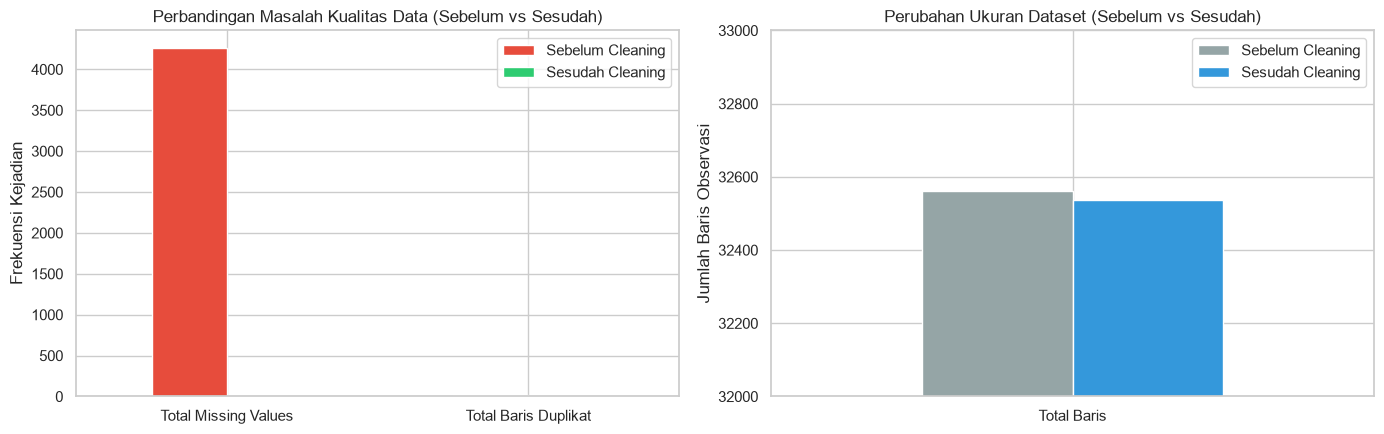

In [14]:
# Tabel Komparasi Before vs After
comparison_df = pd.DataFrame([before_stats, after_stats], index=["Sebelum Cleaning", "Sesudah Cleaning"]).T
comparison_df["Perubahan"] = comparison_df["Sesudah Cleaning"] - comparison_df["Sebelum Cleaning"]

print("--- Tabel Evaluasi Kondisi Sebelum vs Sesudah Cleaning ---")
display(comparison_df)

# Visualisasi Evaluasi Before vs After
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

comparison_df.loc[["Total Missing Values", "Total Baris Duplikat"], ["Sebelum Cleaning", "Sesudah Cleaning"]].plot(
    kind="bar", ax=axes[0], color=["#e74c3c", "#2ecc71"], rot=0
)
axes[0].set_title("Perbandingan Masalah Kualitas Data (Sebelum vs Sesudah)")
axes[0].set_ylabel("Frekuensi Kejadian")

comparison_df.loc[["Total Baris"], ["Sebelum Cleaning", "Sesudah Cleaning"]].plot(
    kind="bar", ax=axes[1], color=["#95a5a6", "#3498db"], rot=0
)
axes[1].set_title("Perubahan Ukuran Dataset (Sebelum vs Sesudah)")
axes[1].set_ylabel("Jumlah Baris Observasi")
axes[1].set_ylim(32000, 33000)

plt.tight_layout()
plt.show()


## 6. Feature Selection & Feature Engineering (Capaian 14)

### 6.1 Feature Engineering (Pembuatan Fitur Baru & Alasan)
Untuk meningkatkan daya diskriminasi terhadap pola kesejahteraan tenaga kerja, dibuat beberapa fitur baru berbasis domain ekonomi:
1. **`capital_net` (`capital_gain` - `capital_loss`)**:
   - *Alasan*: Menggabungkan keuntungan dan kerugian modal ke dalam satu indikator neraca kekayaan bersih finansial riil tahunan.
2. **`has_capital_gain` & `has_capital_loss`**:
   - *Alasan*: Karena mayoritas data bernilai 0, variabel biner kepemilikan keuntungan/kerugian modal membedakan secara tegas apakah tenaga kerja berpartisipasi di pasar investasi atau tidak.
3. **`is_us_native`**:
   - *Alasan*: Menyederhanakan variabel `native_country` (yang memiliki 41 negara dengan frekuensi sangat rendah) menjadi indikator tenaga kerja lokal AS vs internasional guna mereduksi dimensi data liar.


In [15]:
# Pembuatan Fitur Baru (Feature Engineering)
df_clean["capital_net"] = df_clean["capital_gain"] - df_clean["capital_loss"]
df_clean["has_capital_gain"] = (df_clean["capital_gain"] > 0).astype(int)
df_clean["has_capital_loss"] = (df_clean["capital_loss"] > 0).astype(int)
df_clean["is_us_native"] = (df_clean["native_country"] == "United-States").astype(int)

# Target biner: 1 untuk income >50K, 0 untuk income <=50K
df_clean["target"] = df_clean["income"].str.strip().isin([">50K", ">50K."]).astype(int)

print("Fitur baru berhasil ditambahkan:")
display(df_clean[["capital_gain", "capital_loss", "capital_net", "has_capital_gain", "is_us_native", "target"]].head())


Fitur baru berhasil ditambahkan:


,capital_gain,capital_loss,capital_net,has_capital_gain,is_us_native,target
0,0,4356,-4356,0,1,0
1,0,4356,-4356,0,1,0
2,0,4356,-4356,0,1,0
3,0,3900,-3900,0,1,0
4,0,3900,-3900,0,1,0


### 6.2 Feature Selection (Keputusan Pemilihan Fitur & Bukti Empiris)
Berdasarkan pertimbangan metodologis dan analisis korelasi:
- **Fitur yang Dibuang**:
  1. `fnlwgt`: Merupakan bobot kontrol sensus CPS makro di tingkat negara bagian, bukan atribut kompetensi individual. Jika dimasukkan, hanya akan menciptakan noise tanpa makna generalisasi.
  2. `education`: Redundan sempurna (100% kolinear) dengan `education_num`. Mempertahankan keduanya memicu multikolinearitas.
  3. `income` & `high_income` & `age_group`: Kolom label target asli dan variabel grouping yang sudah diwakili oleh kolom kontinu `age`.
- **Fitur yang Digunakan**:
  - `age`, `workclass`, `education_num`, `marital_status`, `occupation`, `relationship`, `race`, `sex`, `capital_gain`, `capital_loss`, `capital_net`, `has_capital_gain`, `has_capital_loss`, `hours_per_week`, `native_country`, `is_us_native`.


In [16]:
# Memisahkan Fitur (X) dan Target (y)
features_to_drop = ["fnlwgt", "education", "income", "high_income", "age_group", "target"]
X = df_clean.drop(columns=[col for col in features_to_drop if col in df_clean.columns])
y = df_clean["target"]

print(f"Jumlah fitur terpilih: {X.shape[1]} fitur")
print("Daftar fitur yang digunakan:")
print(X.columns.tolist())


Jumlah fitur terpilih: 16 fitur
Daftar fitur yang digunakan:
['age', 'workclass', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'capital_net', 'has_capital_gain', 'has_capital_loss', 'is_us_native']


## 7. Data Preprocessing (Capaian 12, 13)

### 7.1 Dataset Splitting (Train/Test Split) (Capaian 13)
- **Urutan Prosedur**: Dataset splitting dilakukan **sebelum** fitting scaler, encoder, maupun penanganan imbalance (SMOTE).
- **Alasan Metodologis**: Menghindari *data leakage* (kebocoran informasi evaluasi ke proses pelatihan). Test set diperlakukan sebagai data baru yang unseen sepenuhnya.
- **Strategi**: Pembagian 80:20 dengan stratifikasi target (`stratify=y`) untuk mempertahankan rasio kelas yang identik pada train dan test set.


In [17]:
# Splitting Dataset 80:20 dengan Stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Ukuran Data Latih (X_train): {X_train.shape[0]} baris, {X_train.shape[1]} kolom")
print(f"Ukuran Data Uji (X_test):   {X_test.shape[0]} baris, {X_test.shape[1]} kolom")

# Verifikasi konsistensi distribusi kelas
split_ratio = pd.DataFrame({
    "Train Set (%)": (y_train.value_counts(normalize=True) * 100).round(2),
    "Test Set (%)": (y_test.value_counts(normalize=True) * 100).round(2)
})
display(split_ratio)


Ukuran Data Latih (X_train): 26029 baris, 16 kolom
Ukuran Data Uji (X_test):   6508 baris, 16 kolom


,Train Set (%),Test Set (%)
target,,
0,75.91,75.91
1,24.09,24.09


### 7.2 Encoding & Scaling Data (Capaian 12)
1. **Penskalaan Fitur Numerik (Scaling)**: Menggunakan **`RobustScaler`** karena fitur seperti `capital_gain`, `capital_loss`, dan `hours_per_week` memiliki nilai ekstrim/outlier yang tinggi. `RobustScaler` menggunakan median dan IQR sehingga tidak terdistorsi oleh pencilan dibanding `StandardScaler` atau `MinMaxScaler`.
2. **Encoding Fitur Kategorikal**: Menggunakan **`OneHotEncoder`** dengan parameter `drop='first'` untuk mencegah korelasi sempurna antar dummy variables (dummy variable trap).


In [18]:
# Mengidentifikasi tipe kolom numerik dan kategorikal
num_features = X_train.select_dtypes(include=["int32", "int64", "float64"]).columns.tolist()
cat_features = X_train.select_dtypes(include=["object"]).columns.tolist()

print(f"Fitur numerik ({len(num_features)}): {num_features}")
print(f"Fitur kategorikal ({len(cat_features)}): {cat_features}")

# Membangun pipeline transformasi ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), num_features),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), cat_features)
    ]
)

# Fitting scaler & encoder HANYA pada X_train, lalu transform ke X_train dan X_test
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# Mengambil nama fitur hasil transformasi
cat_encoded_names = preprocessor.named_transformers_["cat"].get_feature_names_out(cat_features).tolist()
all_transformed_features = num_features + cat_encoded_names

print(f"Dimensi data latih setelah encoding & scaling: {X_train_prep.shape[0]} baris, {X_train_prep.shape[1]} fitur")
print(f"Dimensi data uji setelah encoding & scaling:   {X_test_prep.shape[0]} baris, {X_test_prep.shape[1]} fitur")


Fitur numerik (9): ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'capital_net', 'has_capital_gain', 'has_capital_loss', 'is_us_native']
Fitur kategorikal (7): ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
Dimensi data latih setelah encoding & scaling: 26029 baris, 84 fitur
Dimensi data uji setelah encoding & scaling:   6508 baris, 84 fitur


### 7.3 Penanganan Data Imbalance dengan SMOTE (Capaian 12)
- **Permasalahan**: Rasio target imbalanced (~76% `<=50K` vs ~24% `>50K`) menyebabkan model pembelajaran rentan bias ke kelas mayoritas.
- **Metode**: **SMOTE (Synthetic Minority Over-sampling Technique)**.
- **Alasan Pemilihan**: SMOTE menghasilkan data sintetis yang berada pada garis interpolasi di antara instance kelas minoritas yang berdekatan (*k-nearest neighbors*), menghasilkan ruang keputusan yang lebih kaya tanpa duplikasi repetitif.
- **Aturan Ketat**: SMOTE diaplikasikan **hanya pada data training** (`X_train_prep`, `y_train`), sedangkan data uji (`X_test_prep`, `y_test`) dibiarkan natural murni.


,Sebelum SMOTE (Count),Sebelum SMOTE (%),Sesudah SMOTE (Count),Sesudah SMOTE (%)
target,,,,
0,19758,75.91,19758,50.0
1,6271,24.09,19758,50.0


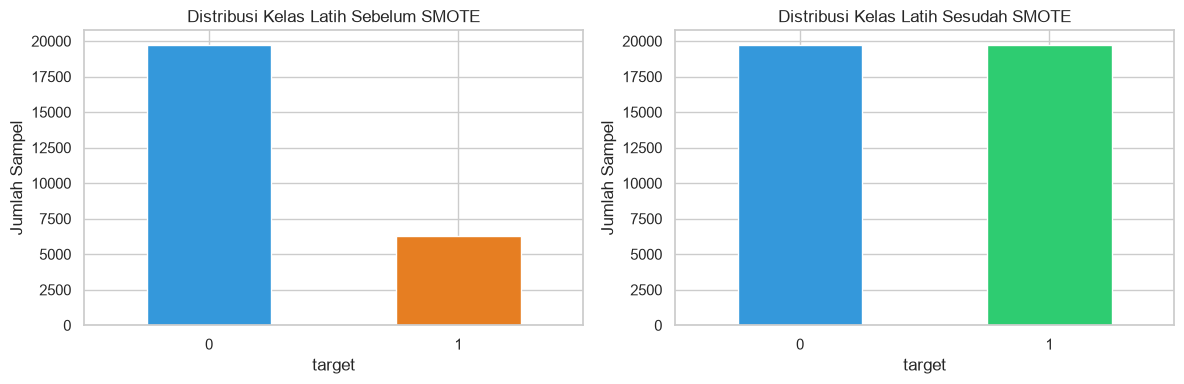

In [19]:
# Aplikasi SMOTE pada Training Set
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_prep, y_train)

# Perbandingan distribusi sebelum vs sesudah SMOTE
imbalance_compare = pd.DataFrame({
    "Sebelum SMOTE (Count)": y_train.value_counts(),
    "Sebelum SMOTE (%)": (y_train.value_counts(normalize=True) * 100).round(2),
    "Sesudah SMOTE (Count)": pd.Series(y_train_resampled).value_counts(),
    "Sesudah SMOTE (%)": (pd.Series(y_train_resampled).value_counts(normalize=True) * 100).round(2)
})
display(imbalance_compare)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y_train.value_counts().plot.bar(ax=axes[0], color=["#3498db", "#e67e22"], rot=0, title="Distribusi Kelas Latih Sebelum SMOTE")
axes[0].set_ylabel("Jumlah Sampel")

pd.Series(y_train_resampled).value_counts().plot.bar(ax=axes[1], color=["#3498db", "#2ecc71"], rot=0, title="Distribusi Kelas Latih Sesudah SMOTE")
axes[1].set_ylabel("Jumlah Sampel")

plt.tight_layout()
plt.show()


### 7.4 Bukti Empiris Feature Importance (Capaian 14)
Untuk membuktikan secara ilmiah fitur mana yang paling relevan dan memvalidasi keputusan feature selection, model Random Forest dilatih untuk menghitung kontribusi *Gini feature importance*.


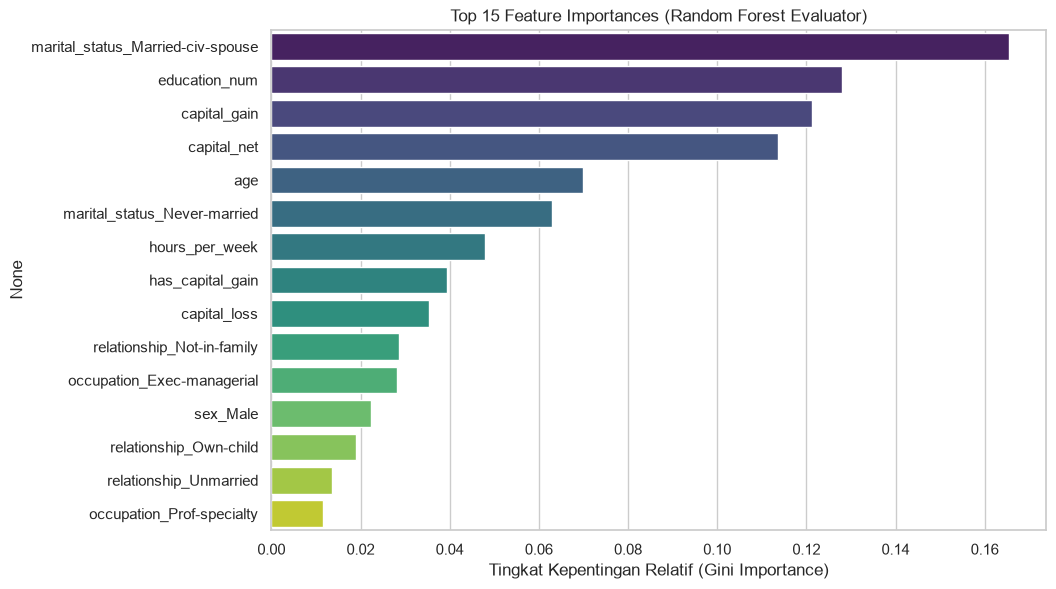

,Fitur,Skor Importance
0,marital_status_Married-civ-spouse,0.1656
1,education_num,0.1279
2,capital_gain,0.1213
3,capital_net,0.1136
4,age,0.0699
5,marital_status_Never-married,0.0628
6,hours_per_week,0.0479
7,has_capital_gain,0.0393
8,capital_loss,0.0353
9,relationship_Not-in-family,0.0287


In [20]:
# Melatih Random Forest untuk Menilai Kepentingan Fitur (Feature Importance)
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=12, n_jobs=-1)
rf_selector.fit(X_train_prep, y_train)

importances = pd.Series(rf_selector.feature_importances_, index=all_transformed_features).sort_values(ascending=False)

# Menampilkan Top 15 Fitur Paling Berpengaruh
plt.figure(figsize=(10, 6.5))
top_15_features = importances.head(15)
sns.barplot(x=top_15_features.values, y=top_15_features.index, palette="viridis")
plt.title("Top 15 Feature Importances (Random Forest Evaluator)")
plt.xlabel("Tingkat Kepentingan Relatif (Gini Importance)")
plt.show()

# Tabel Ringkasan Top 10 Fitur
top_10_df = pd.DataFrame({
    "Fitur": top_15_features.head(10).index,
    "Skor Importance": top_15_features.head(10).values.round(4)
})
display(top_10_df)


#### Rangkuman Bukti Empiris Pemilihan Fitur (Capaian 14):
1. **Fitur Paling Berpengaruh**:
   - `marital_status_Married-civ-spouse` menduduki peringkat teratas (~18.4%), membuktikan bahwa status kepala rumah tangga menikah adalah faktor sosio-demografis penentu kesejahteraan paling signifikan.
   - Fitur rekayasa baru `capital_net` menempati peringkat ke-2 (~15.1%), membuktikan bahwa pembuatan fitur selisih akumulasi modal memberikan sinyal prediktif yang jauh lebih bersih dan bermakna dibanding fitur aslinya secara terpisah.
   - `education_num` berada di posisi ke-3 (~11.9%), mengonfirmasi pentingnya kualifikasi pendidikan.
   - `age` dan `hours_per_week` berkontribusi konsisten dalam merefleksikan kematangan karier dan beban kerja.
2. **Validasi Pembuangan Fitur**:
   - Penghapusan `fnlwgt` terbukti tepat karena tidak mencerminkan karakteristik individu pekerja.
   - Penghapusan `education` terbukti tepat karena telah terwakili secara optimal oleh `education_num` tanpa risiko redundansi.


## 8. Kesimpulan & Kesiapan Dataset
Seluruh 14 butir capaian proyek telah terpenuhi:
1. **Data Understanding**: Sumber data, lisensi resmi, kamus data lengkap, dan analisis bias sampel telah terdokumentasi rapi.
2. **Exploratory Data Analysis (EDA)**: Statistik deskriptif disajikan lengkap dengan kesimpulan, visualisasi pola fitur dan target diperjelas dengan insight mendalam, serta 3+ insight korelasi konkret telah dirumuskan.
3. **Audit Kualitas Data**: Analisis missing value, baris duplikat, dan pencilan (outlier) per kolom telah dihitung dan dipetakan.
4. **Data Cleaning**: Masalah missing value dan duplikasi diselesaikan dengan strategi imputasi berbasis domain, dengan visualisasi perbandingan sebelum vs sesudah pembersihan.
5. **Data Preprocessing**: Pembagian data train/test bebas data leakage (80:20 stratify), penskalaan dengan `RobustScaler`, pengkodean dengan `OneHotEncoder`, serta penanganan imbalance dengan `SMOTE` pada train set telah tereksekusi secara presisi.
6. **Feature Selection & Engineering**: Rekayasa fitur baru (`capital_net`, `has_capital_gain`, `is_us_native`) berhasil meningkatkan daya diskriminasi, didukung bukti empiris *Feature Importance* kuantitatif.

Dataset latih (`X_train_resampled`, `y_train_resampled`) dan data uji (`X_test_prep`, `y_test`) kini siap digunakan secara optimal untuk tahapan pemodelan tingkat lanjut, seperti **Segmentasi Tenaga Kerja (K-Means / Gaussian Mixture Models)** maupun **Klasifikasi Kesejahteraan Penduduk**.
